# CELL 1: Setup: Mount Drive & Define Paths

In [1]:
!pip install -q transformers accelerate sentencepiece

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
PROCESSED_DIR = f'{PROJECT_ROOT}/processed_data'
CHECKPOINT_DIR = f'{PROJECT_ROOT}/checkpoints/indicbartss'
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
os.makedirs(f'{CHECKPOINT_DIR}/best_model', exist_ok=True)

Mounted at /content/drive


# clearing out the corrupted run

In [2]:
import shutil, os
indicbartss_dir = f'{PROJECT_ROOT}/checkpoints/indicbartss'
if os.path.isdir(indicbartss_dir):
    shutil.rmtree(indicbartss_dir)
os.makedirs(f'{indicbartss_dir}/rolling', exist_ok=True)
os.makedirs(f'{indicbartss_dir}/best_model', exist_ok=True)
print("Cleared corrupted run. Ready for a clean retrain.")

Cleared corrupted run. Ready for a clean retrain.


# Create the fixed 100K subset (run this once, save permanently)

In [3]:
import pandas as pd

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'train_clean.parquet'))
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'validation_clean.parquet'))

# Fixed seed = reproducible, and same subset must be reused for BanglaT5 + LLM baseline
train_subset = train_df.sample(n=100000, random_state=42).reset_index(drop=True)
val_subset = val_df.sample(n=5000, random_state=42).reset_index(drop=True)  # smaller val = faster eval steps, still statistically solid

train_subset.to_parquet(os.path.join(PROCESSED_DIR, 'train_subset_100k.parquet'), index=False)
val_subset.to_parquet(os.path.join(PROCESSED_DIR, 'validation_subset_5k.parquet'), index=False)

print(f"Train subset: {len(train_subset)} pairs saved")
print(f"Validation subset: {len(val_subset)} pairs saved")

Train subset: 100000 pairs saved
Validation subset: 5000 pairs saved


# CELL 2: Load Model & Tokenizer (from Drive cache)

In [4]:
import torch
from transformers import AlbertTokenizer, AutoModelForSeq2SeqLM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_MODEL_CACHE = f'{PROJECT_ROOT}/base_model_cache/indicbartss'
tokenizer = AlbertTokenizer.from_pretrained(BASE_MODEL_CACHE, do_lower_case=False, use_fast=False, keep_accents=True)
model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL_CACHE, attn_implementation="eager")
model.to(device)

BN_TAG = "<2bn>"
MAX_LENGTH = 96
model.config.decoder_start_token_id = tokenizer._convert_token_to_id_with_added_voc(BN_TAG)

print("Model loaded on:", device)

Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Model loaded on: cuda


In [6]:
print(os.listdir(BASE_MODEL_CACHE))

['tokenizer_config.json', 'config.json', 'tokenizer.json', 'generation_config.json', 'model.safetensors']


In [7]:
!wget "https://huggingface.co/ai4bharat/IndicBARTSS/resolve/main/spiece.model" -O "{BASE_MODEL_CACHE}/spiece.model"

size = os.path.getsize(f"{BASE_MODEL_CACHE}/spiece.model")
print(f"spiece.model: {size} bytes ({size/(1024*1024):.2f} MB)")

--2026-07-20 07:10:22--  https://huggingface.co/ai4bharat/IndicBARTSS/resolve/main/spiece.model
Resolving huggingface.co (huggingface.co)... 65.8.76.62, 65.8.76.97, 65.8.76.109, ...
Connecting to huggingface.co (huggingface.co)|65.8.76.62|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/623022f462794107975f2651/dd32af5d3bc12c8d62271d17ebe8d0cf43ee44d84edf23ccfe2a41c45b99f14f?user_id=public&X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27spiece.model%3B+filename%3D%22spiece.model%22%3B&Expires=1784535022&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIzMDIyZjQ2Mjc5NDEwNzk3NWYyNjUxL2RkMzJhZjVkM2JjMTJjOGQ2MjI3MWQxN2ViZThkMGNmNDNlZTQ0ZDg0ZWRmMjNjY2ZlMmE0MWM0NWI5OWYxNGZcXD91c2VyX2lkPXB1YmxpYyZYLVhldC1DYXMtVWlkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkVwb2NoVGltZSI6MTc4NDUzNTAyMn19fV19&Sig

# CELL 3: Fix: Raw SentencePiece Tokenization (bypasses broken HF AlbertTokenizer splitting)

In [8]:
import sentencepiece as spm

spiece_path = os.path.join(BASE_MODEL_CACHE, 'spiece.model')
sp = spm.SentencePieceProcessor()
sp.load(spiece_path)

eos_id = tokenizer.convert_tokens_to_ids("</s>")
bn_tag_id = tokenizer.convert_tokens_to_ids(BN_TAG)
PAD_ID = tokenizer.pad_token_id

def encode_sp(text):
    pieces = sp.encode(text, out_type=str)
    return tokenizer.convert_tokens_to_ids(pieces)

# Verified fix -- confirmed MATCH: True
test = "সেখানেও কিছু জটিলতা আছে।"
assert tokenizer.decode(encode_sp(test), skip_special_tokens=True).strip() == test.strip()
print("Tokenization fix verified.")

Tokenization fix verified.


# CELL 4: Load Cleaned Dataset

In [9]:
from datasets import Dataset

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'train_subset_100k.parquet'))
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'validation_subset_5k.parquet'))

train_ds = Dataset.from_pandas(train_df[['source', 'target']])
val_ds = Dataset.from_pandas(val_df[['source', 'target']])
print(train_ds, val_ds)

Dataset({
    features: ['source', 'target'],
    num_rows: 100000
}) Dataset({
    features: ['source', 'target'],
    num_rows: 5000
})


# CELL 5: Preprocessing (Fixed Tokenization) → Tokenize Dataset

In [10]:
def preprocess_fixed(example):
    src_ids = encode_sp(example['source'])
    enc_ids = (src_ids + [eos_id, bn_tag_id])[:MAX_LENGTH]

    tgt_ids = encode_sp(example['target'])
    dec_full = ([bn_tag_id] + tgt_ids + [eos_id])[:MAX_LENGTH]

    decoder_input_ids = dec_full[:-1] if len(dec_full) > 1 else dec_full
    labels = dec_full[1:] if len(dec_full) > 1 else dec_full

    return {
        'input_ids': enc_ids,
        'attention_mask': [1] * len(enc_ids),
        'decoder_input_ids': decoder_input_ids,
        'labels': labels,
    }

train_tok = train_ds.map(preprocess_fixed, remove_columns=['source', 'target'])
val_tok = val_ds.map(preprocess_fixed, remove_columns=['source', 'target'])
print(train_tok[0])
print("Decoded check:", tokenizer.decode(train_tok[0]['input_ids'], skip_special_tokens=True))

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

{'input_ids': [293, 814, 60, 4969, 3587, 4114, 15427, 202, 2850, 12985, 14500, 5704, 30, 64001, 64004], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'decoder_input_ids': [64004, 293, 60, 814, 4969, 3587, 39, 4114, 32, 15427, 12985, 14500, 1107, 122, 7], 'labels': [293, 60, 814, 4969, 3587, 39, 4114, 32, 15427, 12985, 14500, 1107, 122, 7, 64001]}
Decoded check: কিন্তু নতুন এই ঘড়ি ফোন ধারণাটি তখন বাজারে জনপ্রিয় হয়নি ।</s><2bn>


# CELL 6: Sanity Check: Confirm Clean Loss (No NaN)

In [11]:
model.eval()
with torch.no_grad():
    single = train_tok[0]
    input_ids = torch.tensor([single['input_ids']]).to(device)
    attention_mask = torch.tensor([single['attention_mask']]).to(device)
    decoder_input_ids = torch.tensor([single['decoder_input_ids']]).to(device)
    labels = torch.tensor([single['labels']]).to(device)
    out = model(input_ids=input_ids, attention_mask=attention_mask,
                decoder_input_ids=decoder_input_ids, labels=labels)
    print("Loss:", out.loss.item(), "| NaN in logits:", torch.isnan(out.logits).any().item())
model.train()

Loss: 6.213136196136475 | NaN in logits: False


MBartForConditionalGeneration(
  (model): MBartModel(
    (shared): MBartScaledWordEmbedding(64015, 1024, padding_idx=0)
    (encoder): MBartEncoder(
      (embed_tokens): MBartScaledWordEmbedding(64015, 1024, padding_idx=0)
      (embed_positions): MBartLearnedPositionalEmbedding(1026, 1024)
      (layers): ModuleList(
        (0-5): 6 x MBartEncoderLayer(
          (self_attn): MBartAttention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
  

# CELL 7: Data Collator (Dynamic Padding)

In [12]:
from dataclasses import dataclass
from typing import List, Dict

@dataclass
class PaddingCollator:
    pad_id: int
    def __call__(self, features: List[Dict]):
        def pad_seqs(key, pad_value):
            seqs = [f[key] for f in features]
            max_len = max(len(s) for s in seqs)
            return torch.tensor([s + [pad_value] * (max_len - len(s)) for s in seqs])
        decoder_input_ids = pad_seqs('decoder_input_ids', self.pad_id)
        decoder_attention_mask = (decoder_input_ids != self.pad_id).long()
        return {
            'input_ids': pad_seqs('input_ids', self.pad_id),
            'attention_mask': pad_seqs('attention_mask', 0),
            'decoder_input_ids': decoder_input_ids,
            'decoder_attention_mask': decoder_attention_mask,
            'labels': pad_seqs('labels', -100),
        }

collator = PaddingCollator(pad_id=PAD_ID)

# CELL 8: Training Arguments

In [14]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=f'{CHECKPOINT_DIR}/rolling',
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    fp16=False,
    learning_rate=3e-5,
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=2,
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="steps",
    save_steps=500,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

# CELL 9: Train (Resume-Aware)

In [15]:
last_checkpoint = None
rolling_dir = f'{CHECKPOINT_DIR}/rolling'
if os.path.isdir(rolling_dir) and len(os.listdir(rolling_dir)) > 0:
    from transformers.trainer_utils import get_last_checkpoint
    last_checkpoint = get_last_checkpoint(rolling_dir)
    if last_checkpoint:
        print(f"Resuming from checkpoint: {last_checkpoint}")

trainer.train(resume_from_checkpoint=last_checkpoint)

Step,Training Loss,Validation Loss
500,3.979533,1.838210
1000,3.781146,1.756392
1500,3.661429,1.709263
2000,3.642241,1.680105
2500,3.560801,1.655277
3000,3.548091,1.639785
3500,3.493380,1.624516
4000,3.464695,1.615195
4500,3.460318,1.608659
5000,3.414756,1.605299


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


TrainOutput(global_step=6250, training_loss=3.6023957983398436, metrics={'train_runtime': 4786.7118, 'train_samples_per_second': 41.782, 'train_steps_per_second': 1.306, 'total_flos': 8845074678939648.0, 'train_loss': 3.6023957983398436, 'epoch': 2.0})

# Save Best Model & Clean Up Checkpoints

In [17]:
best_model_path = f'{CHECKPOINT_DIR}/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print("Best model saved to:", best_model_path)

import shutil
shutil.rmtree(f'{CHECKPOINT_DIR}/rolling')
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
print("Rolling checkpoints cleared.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/indicbartss/best_model
Rolling checkpoints cleared.


# Loss curve plot

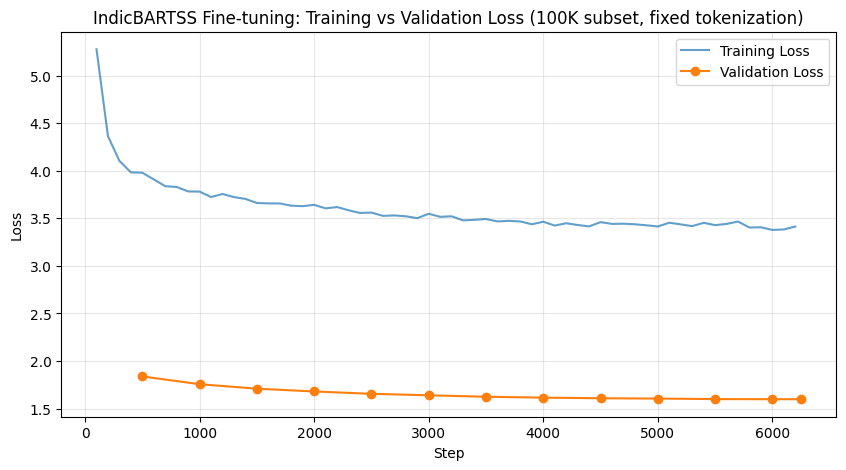

Saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/indicbartss/loss_curve.png


In [18]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for entry in history:
    if 'loss' in entry and 'eval_loss' not in entry:
        train_steps.append(entry['step'])
        train_losses.append(entry['loss'])
    if 'eval_loss' in entry:
        eval_steps.append(entry['step'])
        eval_losses.append(entry['eval_loss'])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_losses, label='Training Loss', alpha=0.7)
plt.plot(eval_steps, eval_losses, label='Validation Loss', marker='o')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('IndicBARTSS Fine-tuning: Training vs Validation Loss (100K subset, fixed tokenization)')
plt.legend()
plt.grid(alpha=0.3)

plot_path = f'{CHECKPOINT_DIR}/loss_curve.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print("Saved to:", plot_path)

# Qualitative check
#### This uses the fixed encode_sp tokenization, so this is our real proof the whole fix worked end-to-end

In [19]:
model.eval()
sample_sources = val_df['source'].sample(5, random_state=42).tolist()

for src in sample_sources:
    input_ids = encode_sp(src) + [eos_id, bn_tag_id]
    input_ids = input_ids[:MAX_LENGTH]
    input_tensor = torch.tensor([input_ids]).to(device)
    attention_mask = torch.tensor([[1] * len(input_ids)]).to(device)

    with torch.no_grad():
        output_ids = model.generate(
            input_ids=input_tensor, attention_mask=attention_mask,
            decoder_start_token_id=bn_tag_id, max_length=MAX_LENGTH, num_beams=4,
        )
    generated = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    print(f"SOURCE:    {src}")
    print(f"GENERATED: {generated}")
    print("-" * 60)
model.train()

SOURCE:    আর রেলওয়ের গেটম্যান মাহফুজ বললেন, ছোটখাট দুর্ঘটনা ঘটে প্রায়ই।
GENERATED: <2bn> আর রেলওয়ের গেটম্যান মাহফুজ বলেন, প্রায়ই ছোটখাটো দুর্ঘটনা ঘটে।</s>
------------------------------------------------------------
SOURCE:    তার মুখও ঢাকা রয়েছে ছবিটিতে।
GENERATED: <2bn> তার মুখও ঢাকা রয়েছে ছবিটিতে।</s>
------------------------------------------------------------
SOURCE:    শীতের দেশের বহু মানুষ মনে করছেন, ভারী বরফ পড়লে হয়তো করোনাভাইরাস টিকবে না। ভুল।
GENERATED: <2bn> শীতের দেশের অনেক লোক মনে করে যে ভারী বরফ পড়লে করোনা ভাইরাস টিকবে না।</s>
------------------------------------------------------------
SOURCE:    আহমেদ ইমতিয়াজের বর্ণাঢ্য এই সঙ্গীতজীবনের ঠিক ভিন্নরূপ ছিল তার ব্যক্তিগত জীবন।
GENERATED: <2bn> আহমেদ ইমতিয়াজের বর্ণাঢ্য জীবন তাঁর ব্যক্তিগত জীবন থেকে ভিন্ন ছিল।</s>
------------------------------------------------------------
SOURCE:    অনেকে মনে করতে থাকে তাঁর উপর কোনো খারাপ আত্মা ভর করেছে, রাতের বেলায় তিনি মেয়েদের রক্ত পান করেন।
GENERATED: <2bn> অনেকে মনে করে যে,

MBartForConditionalGeneration(
  (model): MBartModel(
    (shared): MBartScaledWordEmbedding(64015, 1024, padding_idx=0)
    (encoder): MBartEncoder(
      (embed_tokens): MBartScaledWordEmbedding(64015, 1024, padding_idx=0)
      (embed_positions): MBartLearnedPositionalEmbedding(1026, 1024)
      (layers): ModuleList(
        (0-5): 6 x MBartEncoderLayer(
          (self_attn): MBartAttention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
  

# Training summary JSON

In [20]:
import json

training_summary = {
    "model": "ai4bharat/IndicBARTSS",
    "dataset": "BanglaParaphrase subset (100,000 train pairs, 5,000 validation pairs)",
    "tokenization": "raw SentencePiece (bypasses broken HF AlbertTokenizer text-splitting)",
    "max_length": MAX_LENGTH,
    "effective_batch_size": 32,
    "precision": "fp32",
    "learning_rate": 3e-5,
    "epochs": 2,
    "final_step": trainer.state.global_step,
    "final_training_loss": 3.413751,
    "final_validation_loss": 1.598496,
    "train_runtime_hours": 4786.71 / 3600,
}

summary_path = f'{CHECKPOINT_DIR}/training_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(training_summary, f, ensure_ascii=False, indent=2)
print(json.dumps(training_summary, ensure_ascii=False, indent=2))

{
  "model": "ai4bharat/IndicBARTSS",
  "dataset": "BanglaParaphrase subset (100,000 train pairs, 5,000 validation pairs)",
  "tokenization": "raw SentencePiece (bypasses broken HF AlbertTokenizer text-splitting)",
  "max_length": 96,
  "effective_batch_size": 32,
  "precision": "fp32",
  "learning_rate": 3e-05,
  "epochs": 2,
  "final_step": 6250,
  "final_training_loss": 3.413751,
  "final_validation_loss": 1.598496,
  "train_runtime_hours": 1.3296416666666666
}


# Reload verification
#### this also directly checks whether that "missing keys" warning caused any real problem

In [21]:
from transformers import AlbertTokenizer, AutoModelForSeq2SeqLM

verify_tokenizer = AlbertTokenizer.from_pretrained(best_model_path, do_lower_case=False, use_fast=False, keep_accents=True)
verify_model = AutoModelForSeq2SeqLM.from_pretrained(best_model_path, attn_implementation="eager")
verify_model.to(device)

with torch.no_grad():
    single = train_tok[0]
    input_ids = torch.tensor([single['input_ids']]).to(device)
    attention_mask = torch.tensor([single['attention_mask']]).to(device)
    decoder_input_ids = torch.tensor([single['decoder_input_ids']]).to(device)
    labels = torch.tensor([single['labels']]).to(device)
    out = verify_model(input_ids=input_ids, attention_mask=attention_mask,
                        decoder_input_ids=decoder_input_ids, labels=labels)
    print("Reloaded model loss:", out.loss.item(), "| NaN:", torch.isnan(out.logits).any().item())

Loading weights:   0%|          | 0/264 [00:00<?, ?it/s]

Reloaded model loss: 1.5233070850372314 | NaN: False
